In [13]:
from rosca import solve_rosca_milp, simulate_rosca, compute_no_rosca_wait_times, solve_rosca_heuristic
import numpy as np
import matplotlib.pyplot as plt
import json

In [14]:
configs = {
    "uniform": lambda N: {
        "num_people": N,
        "init_bank": 0,
        "init_balances_vec": [0]*N,
        "wages_vec": [1000]*N,
        "goals_vec": [10000]*N,
    },
    "one-different": lambda N: {
        "num_people": N,
        "init_bank": 0,
        "init_balances_vec": [0]*N,
        "wages_vec": [1000]*N,
        "goals_vec": [10000]*(N-1) + [5000],
    },
    "random": lambda N: {
        "num_people": N,
        "init_bank": np.random.randint(low=0, high=1000+1),
        "init_balances_vec": np.random.randint(low=0, high=3000+1, size=N),
        "wages_vec": np.random.randint(low=800, high=1600, size=N),
        "goals_vec": np.random.randint(low=8000, high=16000, size=N),
    }
}

N_last_values = {
    "uniform": 11,
    "one-different": 10,
    "random": 11,
}

In [15]:
NUM_RUNS = 20
N_FIRST = 3

In [16]:
SIM_DATA_PATH = "sim-data.json"

try:
    with open(SIM_DATA_PATH, "r") as f:
        sim_data = json.load(f)
except:
    print("No simulations data found...")
    sim_data = {}

In [17]:
results = {}

for name, config_fn in configs.items():
    print(f"{name}...")

    if name not in sim_data:
        sim_data[name] = {}

    no_rosca_wait_times = []
    rosca_milp_wait_times = []
    rosca_milp_elapsed_times = []
    rosca_heuristic_wait_times = []
    n_values = list(range(N_FIRST, N_last_values[name]+1))

    for N in n_values:
        print(f"  N={N}...")

        if str(N) in sim_data[name]:
            no_rosca_test_wait_times, rosca_milp_test_wait_times, rosca_milp_test_elapsed_times, rosca_heuristic_test_wait_times = sim_data[name][str(N)]
        else:
            no_rosca_test_wait_times = []
            rosca_milp_test_wait_times = []
            rosca_milp_test_elapsed_times = []
            rosca_heuristic_test_wait_times = []

            for _ in range(NUM_RUNS):
                config = config_fn(N)

                # Model 1: trivial (no ROSCA is performed)
                no_rosca_run_wait_times = compute_no_rosca_wait_times(**config)
                no_rosca_test_wait_times.append(sum(no_rosca_run_wait_times))

                config["time"] = max(no_rosca_run_wait_times)

                # Model 2: MILP solver
                _, rosca_milp_run_wait_times, milp_elapsed_t = solve_rosca_milp(name, **config)
                rosca_milp_test_wait_times.append(sum(rosca_milp_run_wait_times))
                rosca_milp_test_elapsed_times.append(milp_elapsed_t)

                # Model 3: heuristic solver
                _, rosca_heuristic_run_wait_times, _ = solve_rosca_heuristic(**config)
                rosca_heuristic_test_wait_times.append(sum(rosca_heuristic_run_wait_times))
            
            sim_data[name][str(N)] = (no_rosca_test_wait_times, rosca_milp_test_wait_times, rosca_milp_test_elapsed_times, rosca_heuristic_test_wait_times)
            with open(SIM_DATA_PATH, "w") as f:
                json.dump(sim_data, f, indent=4)

        no_rosca_wait_times.append(np.mean(no_rosca_test_wait_times))
        rosca_milp_wait_times.append(np.mean(rosca_milp_test_wait_times))
        rosca_milp_elapsed_times.append(np.mean(rosca_milp_test_elapsed_times))
        rosca_heuristic_wait_times.append(np.mean(rosca_heuristic_test_wait_times))

    results[name] = (n_values, no_rosca_wait_times, rosca_milp_wait_times, rosca_milp_elapsed_times, rosca_heuristic_wait_times)

uniform...
  N=3...
  N=4...
  N=5...
  N=6...
  N=7...
  N=8...
  N=9...
  N=10...
  N=11...
one-different...
  N=3...
  N=4...
  N=5...
  N=6...
  N=7...
  N=8...
  N=9...
  N=10...
random...
  N=3...
  N=4...
  N=5...
  N=6...
  N=7...
  N=8...
  N=9...
  N=10...
  N=11...


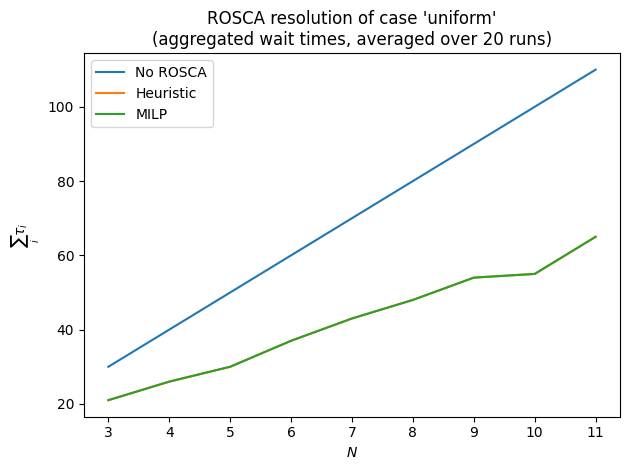

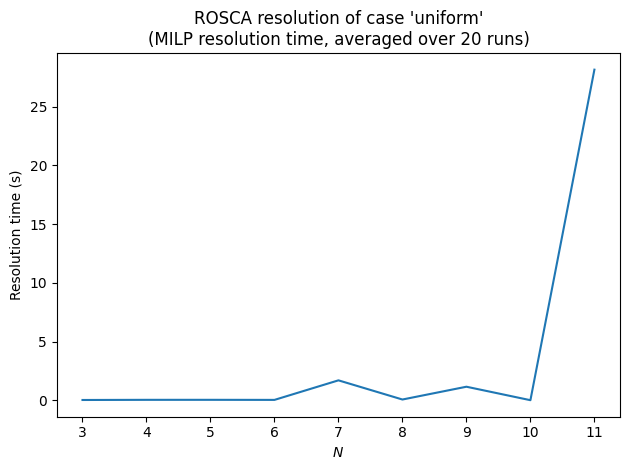

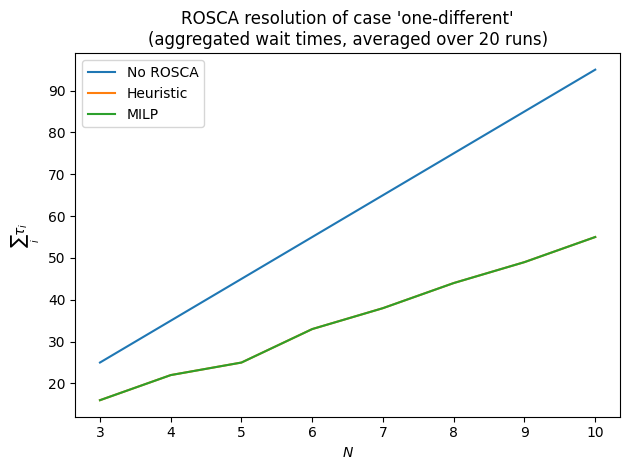

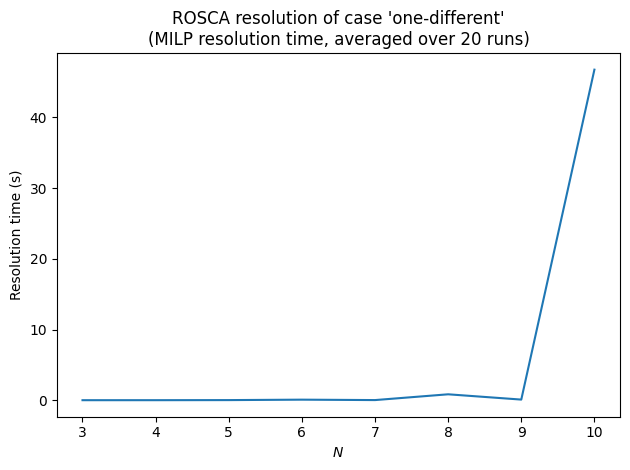

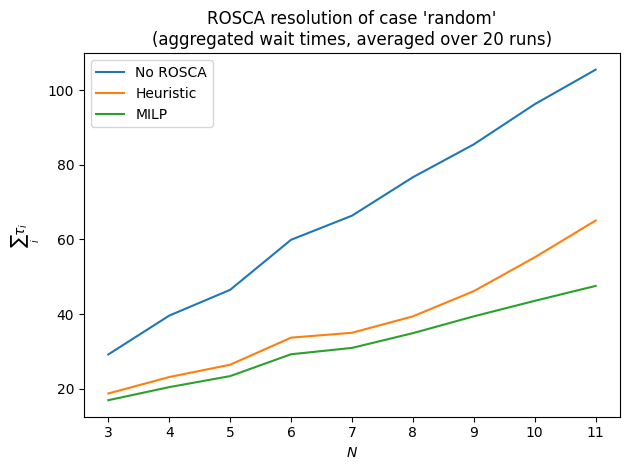

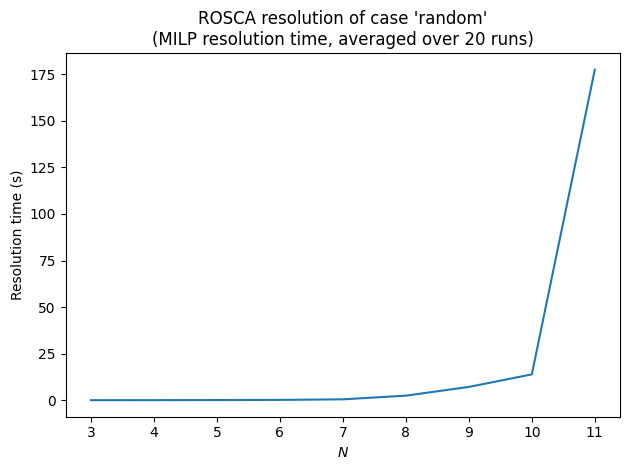

In [18]:
for name, (n_values, no_rosca_wait_times, rosca_milp_wait_times, rosca_milp_elapsed_times, rosca_heuristic_wait_times) in results.items():
    plt.plot(n_values, no_rosca_wait_times, label="No ROSCA")
    plt.plot(n_values, rosca_heuristic_wait_times, label="Heuristic")
    plt.plot(n_values, rosca_milp_wait_times, label="MILP")
    plt.legend()
    plt.title(f"ROSCA resolution of case '{name}'\n(aggregated wait times, averaged over {NUM_RUNS} runs)")
    plt.xlabel("$N$")
    plt.ylabel("$\\sum_i{\\tau_i}$")
    plt.tight_layout()
    plt.savefig(f"plot_{N_FIRST}to{n_values[-1]}_wait_times_{name}.png")
    plt.show()

    plt.plot(n_values, rosca_milp_elapsed_times)
    plt.title(f"ROSCA resolution of case '{name}'\n(MILP resolution time, averaged over {NUM_RUNS} runs)")
    plt.xlabel("$N$")
    plt.ylabel("Resolution time (s)")
    plt.tight_layout()
    plt.savefig(f"plot_{N_FIRST}to{n_values[-1]}_milp_solve_times_{name}.png")
    plt.show()